# Phoenix : pricing tests

A phoenix is an autocallable note of nominal $N$ on the CAC40, with initial fixing $S_{ref}$ and observation
dates $t_1 < \dots < t_n = T$. With $P_k = S_{t_k}/S_{ref}$, at each observation date:
- **coupon**: $N c\,(t_k - t_{k-1})$ is paid if $P_k \ge B^{cpn}_k$; with **memory**, the coupons missed since the
  last payment are paid as well;
- **autocall**: if the date is callable and $P_k \ge B^{call}_k$, the note is redeemed at $N$.

At maturity, if never called: $N$ if the protection is not knocked-in, otherwise
$N \max(\text{floor}, \min(1, P_T / K_{put}))$, with a European or American protection as for the Athena.

Every form is a parameter of `Phoenix` (`Produits/products.py`): coupon barrier, memory, observation frequency,
autocall barrier and step-down, non-call period, protection level and type, airbag, capital guarantee.
With a coupon barrier equal to the autocall barrier and memory, a phoenix is exactly a snowball Athena; with a
coupon barrier at 0, the coupon is unconditional.

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..", "Model")))   # models, Monte Carlo engine, Greeks
sys.path.append(os.path.abspath(".."))                                # Produits : products.py, market.py, notes_analysis.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market import cac40_heston, flat_market
from products import Athena, Phoenix
from monte_carlo import MonteCarloPricer
from greeks import Greeks, bump_vol, bump_carry, plot_greeks_bars, plot_greek_profiles
from notes_analysis import compare_notes, plot_redemption_profiles, plot_call_probabilities, plot_scenarios

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

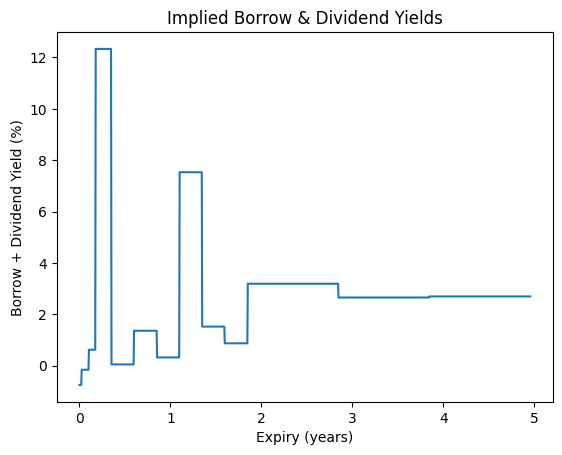

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [2]:
mkt = cac40_heston()
heston, S0 = mkt.heston, mkt.S0
# Weekly grid : observation dates are discrete and the American protection uses the Brownian bridge,
# so a daily grid is only needed for the daily-monitored protection ('american_discrete').
pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=52, seed=42)
daily_pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)

## 1. Mechanics

Base case: 4 years, quarterly observations, coupon of 6% p.a. (1.5% per quarter) with memory and a coupon barrier
at 70%, autocall at 100%, European protection at 60%.

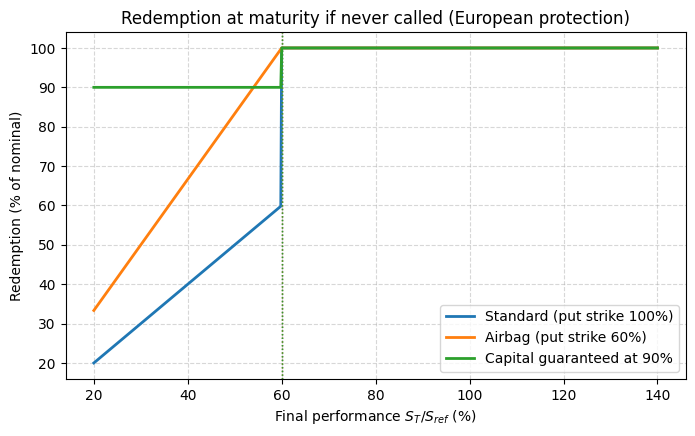

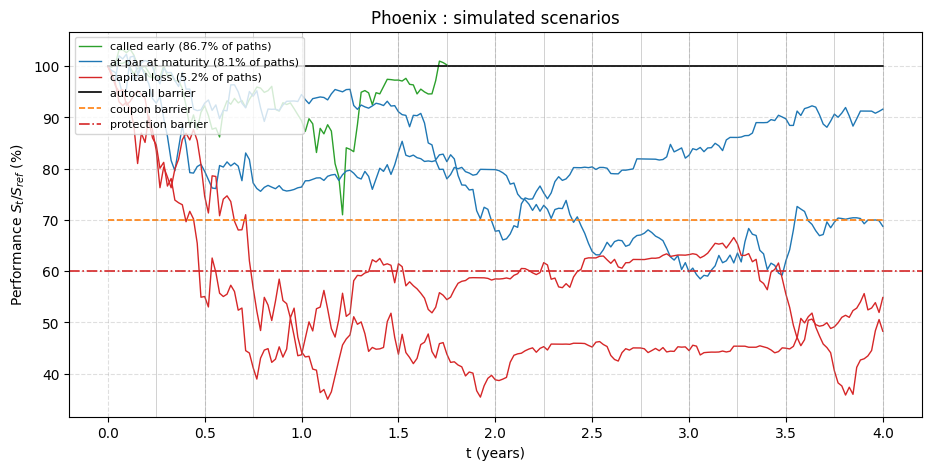

In [3]:
base = Phoenix(4.0, S0, 0.06, coupon_barrier=0.7, memory=True, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6)
plot_redemption_profiles({"Standard (put strike 100%)": base,
                          "Airbag (put strike 60%)": Phoenix(4.0, S0, 0.06, frequency=0.25, put_strike=0.6),
                          "Capital guaranteed at 90%": Phoenix(4.0, S0, 0.06, frequency=0.25, floor=0.9)});
plot_scenarios(pricer, heston, base)

## 2. Validation

1. Flat market, never called and unconditional coupons: $\sum_k N c\,(t_k - t_{k-1}) D(t_k)$ + the protection leg
   of the Athena notebook (closed form).
2. Flat market, called for sure at the first date with a coupon barrier at 0: $N (1 + c\, t_1) D(t_1)$.
3. CAC40: a phoenix with memory and a coupon barrier equal to the autocall barrier must have exactly the price of
   the snowball Athena (same paths).

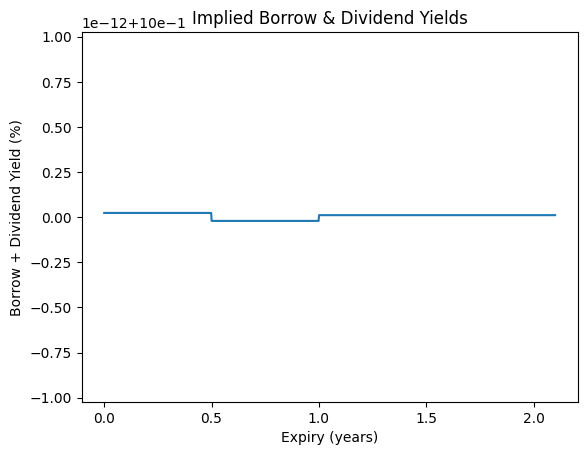

,Reference,Monte Carlo,Std error,Error / std error
"Never called, unconditional coupons (flat)",104.24,104.252,0.0140658,0.792501
Called for sure at t1 = 0.25 (flat),100.742,100.742,0,0
"Memory phoenix, coupon barrier = autocall barrier (CAC40)",98.7669,98.7669,0.0585111,0


In [4]:
flat = flat_market()
fp = MonteCarloPricer(n_paths=100_000, steps_per_year=52, seed=1)
T, N, B, c = 2.0, 100.0, 60.0, 0.06
D = np.exp(-flat.r * T)
put, dput = flat.bs_model.bs_price_vanilla(T, B, flat.sigma, False), flat.bs_model.bs_price_digital(T, B, flat.sigma, False)
dates = np.arange(1, 9) * 0.25
cases = {
    "Never called, unconditional coupons (flat)": (
        Phoenix(T, 100.0, c, coupon_barrier=0.0, autocall_barrier=1e6, frequency=0.25, protection_barrier=0.6),
        N * c * 0.25 * np.exp(-flat.r * dates).sum() + N * D - N / 100 * (put + (100 - B) * dput), flat.heston, fp),
    "Called for sure at t1 = 0.25 (flat)": (
        Phoenix(T, 100.0, c, coupon_barrier=0.0, autocall_barrier=0.0, frequency=0.25),
        N * (1 + c * 0.25) * np.exp(-flat.r * 0.25), flat.heston, fp),
    "Memory phoenix, coupon barrier = autocall barrier (CAC40)": (
        Phoenix(4.0, S0, 0.08, coupon_barrier=1.0, memory=True, frequency=0.25),
        pricer.price(heston, Athena(4.0, S0, 0.08, frequency=0.25, coupon_type="snowball")).price, heston, pricer),
}
rows = {}
for name, (note, exact, model, p) in cases.items():
    res = p.price(model, note)
    rows[name] = {"Reference": exact, "Monte Carlo": res.price, "Std error": res.stderr,
                  "Error / std error": (res.price - exact) / res.stderr if abs(res.price - exact) > 1e-10 else 0.0}
pd.DataFrame(rows).T

## 3. Base case on the CAC40

In [5]:
res = pricer.price(heston, base)
print(f"{base}, coupon barrier 70%, memory")
print(f"Price : {res.price:.3f} +/- {1.96 * res.stderr:.3f} (95%) for a nominal of 100")
print(f"Fair coupon : {100 * base.fair_coupon(pricer, heston):.3f}% p.a.")
stats = base.statistics(pricer, heston)
pd.Series({k: v for k, v in stats.items() if k != "call probability by date"}, name="Base case").to_frame()

Phoenix(T=4, 16 obs, coupon 6.00% p.a., autocall 100%, protection 60% european), coupon barrier 70%, memory
Price : 99.963 +/- 0.099 (95%) for a nominal of 100
Fair coupon : 6.044% p.a.


,Base case
probability to reach maturity,0.1329
probability of a capital loss,0.05218
expected loss at maturity (% nominal),3.05192
expected life (years),1.03247
expected number of coupons,3.28464


## 4. All the forms of the phoenix

Every variant changes one feature of the base case (quarterly, memory, coupon barrier 70%, autocall 100%,
European protection 60%).

In [6]:
q = dict(frequency=0.25)
variants = {
    "Base (quarterly, memory, CB 70%)":  base,
    "No memory":                         Phoenix(4.0, S0, 0.06, memory=False, **q),
    "Coupon barrier 50%":                Phoenix(4.0, S0, 0.06, coupon_barrier=0.5, **q),
    "Coupon barrier 60%":                Phoenix(4.0, S0, 0.06, coupon_barrier=0.6, **q),
    "Coupon barrier 80%":                Phoenix(4.0, S0, 0.06, coupon_barrier=0.8, **q),
    "Coupon barrier = autocall (= snowball Athena)": Phoenix(4.0, S0, 0.06, coupon_barrier=1.0, **q),
    "Unconditional coupon (CB 0%)":      Phoenix(4.0, S0, 0.06, coupon_barrier=0.0, **q),
    "Monthly observations":              Phoenix(4.0, S0, 0.06, frequency=1 / 12),
    "Semi-annual observations":          Phoenix(4.0, S0, 0.06, frequency=0.5),
    "Annual observations":               Phoenix(4.0, S0, 0.06, frequency=1.0),
    "Autocall barrier 90%":              Phoenix(4.0, S0, 0.06, autocall_barrier=0.9, **q),
    "Step-down 1.25% per quarter":       Phoenix(4.0, S0, 0.06, step_down=0.0125, **q),
    "Non-call 1 year":                   Phoenix(4.0, S0, 0.06, first_call_date=1.0, **q),
    "Protection 50%":                    Phoenix(4.0, S0, 0.06, protection_barrier=0.5, **q),
    "Protection 70% (= coupon barrier)": Phoenix(4.0, S0, 0.06, protection_barrier=0.7, **q),
    "American protection (continuous)":  Phoenix(4.0, S0, 0.06, protection_type="american", **q),
    "American protection (daily)":       (Phoenix(4.0, S0, 0.06, protection_type="american_discrete", **q), daily_pricer),
    "Airbag":                            Phoenix(4.0, S0, 0.06, put_strike=0.6, **q),
    "Capital guaranteed 90%":            Phoenix(4.0, S0, 0.06, floor=0.9, **q),
}
start = time.time()
phoenix_variants = compare_notes(pricer, heston, variants)
print(f"{time.time() - start:.1f}s")
phoenix_variants

4.0s


,Coupon p.a. (%),Price,Std error,Fair coupon p.a. (%),P(call at 1st date) (%),P(reach maturity) (%),P(capital loss) (%),Expected loss (%),Expected life (y),Expected coupons,Time (s)
"Base (quarterly, memory, CB 70%)",6,99.9631,0.0502671,6.04354,55.428,13.29,5.218,3.05192,1.03247,3.28464,0.073643
No memory,6,99.673,0.0502524,6.40934,55.428,13.29,5.218,3.05192,1.03247,3.28464,0.0448914
Coupon barrier 50%,6,100.536,0.0447006,5.4311,55.428,13.29,5.218,3.05192,1.03247,3.82518,0.0570154
Coupon barrier 60%,6,100.297,0.0481485,5.67092,55.428,13.29,5.218,3.05192,1.03247,3.60922,0.0536451
Coupon barrier 80%,6,99.4883,0.0519753,6.66633,55.428,13.29,5.218,3.05192,1.03247,2.79552,0.0557275
Coupon barrier = autocall (= snowball Athena),6,97.7953,0.0558793,10.5382,55.428,13.29,5.218,3.05192,1.03247,0.8671,0.0544286
Unconditional coupon (CB 0%),6,100.867,0.0392906,5.13072,55.428,13.29,5.218,3.05192,1.03247,4.12988,0.0501328
Monthly observations,6,99.9073,0.0418611,6.19164,56.21,7.766,3.128,1.83039,0.588053,5.52976,0.123841
Semi-annual observations,6,100.217,0.0541964,5.82004,53.298,18.61,6.972,4.07502,1.47667,2.37514,0.0320797
Annual observations,6,100.618,0.0560489,5.62862,55.692,25.704,9.06,5.27305,2.06456,1.66952,0.023303


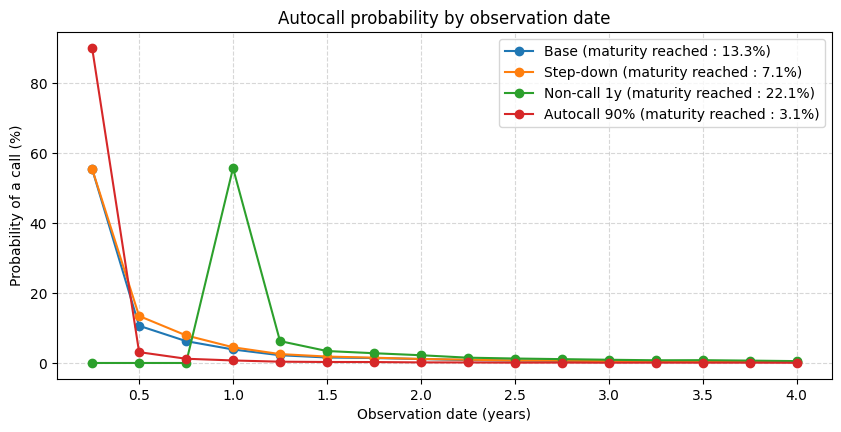

In [7]:
plot_call_probabilities(pricer, heston, {"Base": base, "Step-down": variants["Step-down 1.25% per quarter"],
                                         "Non-call 1y": variants["Non-call 1 year"], "Autocall 90%": variants["Autocall barrier 90%"]})

## 5. Fair coupon as a function of the coupon barrier and of the protection

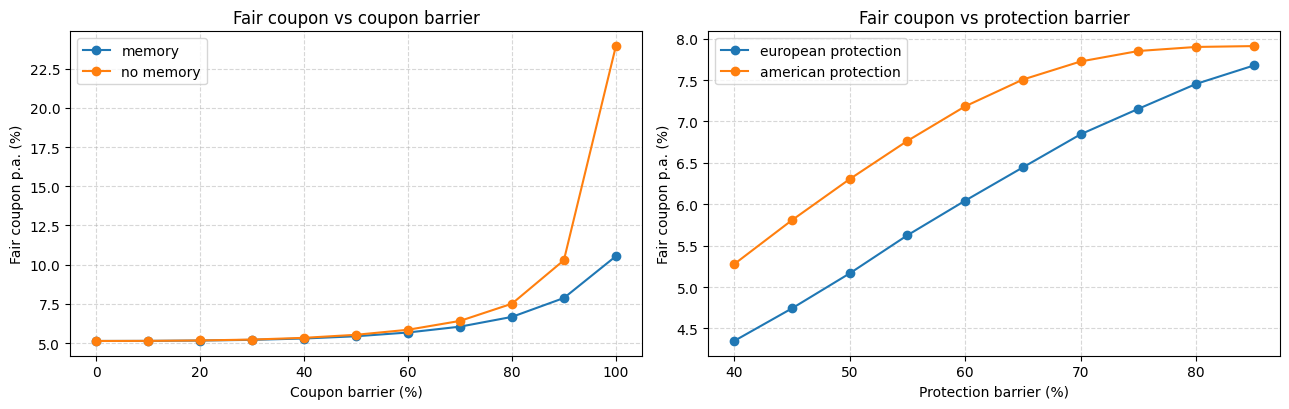

In [8]:
coupon_barriers = np.arange(0.0, 1.001, 0.1)
protections = np.arange(0.40, 0.851, 0.05)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for memory in [True, False]:
    axes[0].plot(100 * coupon_barriers, [100 * Phoenix(4.0, S0, 0.06, coupon_barrier=b, memory=memory, frequency=0.25).fair_coupon(pricer, heston)
                                         for b in coupon_barriers], "o-", label="memory" if memory else "no memory")
for kind in ["european", "american"]:
    axes[1].plot(100 * protections, [100 * Phoenix(4.0, S0, 0.06, protection_barrier=b, protection_type=kind, frequency=0.25).fair_coupon(pricer, heston)
                                     for b in protections], "o-", label=f"{kind} protection")
axes[0].set_xlabel("Coupon barrier (%)"); axes[1].set_xlabel("Protection barrier (%)")
for ax, title in zip(axes, ["Fair coupon vs coupon barrier", "Fair coupon vs protection barrier"]):
    ax.set_ylabel("Fair coupon p.a. (%)"); ax.set_title(title); ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
plt.tight_layout()
plt.show()

## 6. Greeks

Bump and revalue with common random numbers (`Model/greeks.py`), on a nominal of 100. The initial fixing $S_{ref}$
is kept fixed: only the market moves. Units: Delta per index point (multiply by $S_0/100 \approx 80$ for a 1% move),
Gamma per index point squared, Vega and Volga per vol point, Vanna as Delta change per vol point, Rho per +1% of
rates, Dividend per +1% of borrow + dividend yield, Theta per calendar day.

In [9]:
greeks = Greeks(pricer)
notes = [base, variants["No memory"], variants["American protection (continuous)"], variants["Airbag"],
         variants["Unconditional coupon (CB 0%)"]]
labels = ["Base", "No memory", "American protection", "Airbag", "Unconditional coupon"]
start = time.time()
phoenix_greeks = greeks.table(heston, notes, greeks=Greeks.ORDER, with_stderr=True, labels=labels)
print(f"{time.time() - start:.1f}s")
phoenix_greeks[[c for c in phoenix_greeks.columns if not c.endswith("stderr")]]

26.0s


,price,delta,gamma,vega,vanna,volga,rho,dividend,theta
Base,99.9631,0.000586197,-1.22335e-06,-0.334505,0.000613201,-0.00490519,-0.599297,-0.324995,0.00495895
No memory,99.673,0.00105775,-1.27217e-06,-0.364836,0.000627206,-0.002512,-0.560149,-0.356628,0.00533534
American protection,98.9975,0.00228991,-2.68688e-06,-0.394419,0.000572497,0.0120855,-0.448074,-0.437417,0.00389752
Airbag,101.278,-0.00150825,1.14673e-06,-0.224196,0.000538226,-0.00573996,-0.875196,-0.101446,0.00263302
Unconditional coupon,100.867,-0.000771735,1.22973e-06,-0.252636,0.000566715,-0.0062592,-0.744806,-0.201971,0.00480817


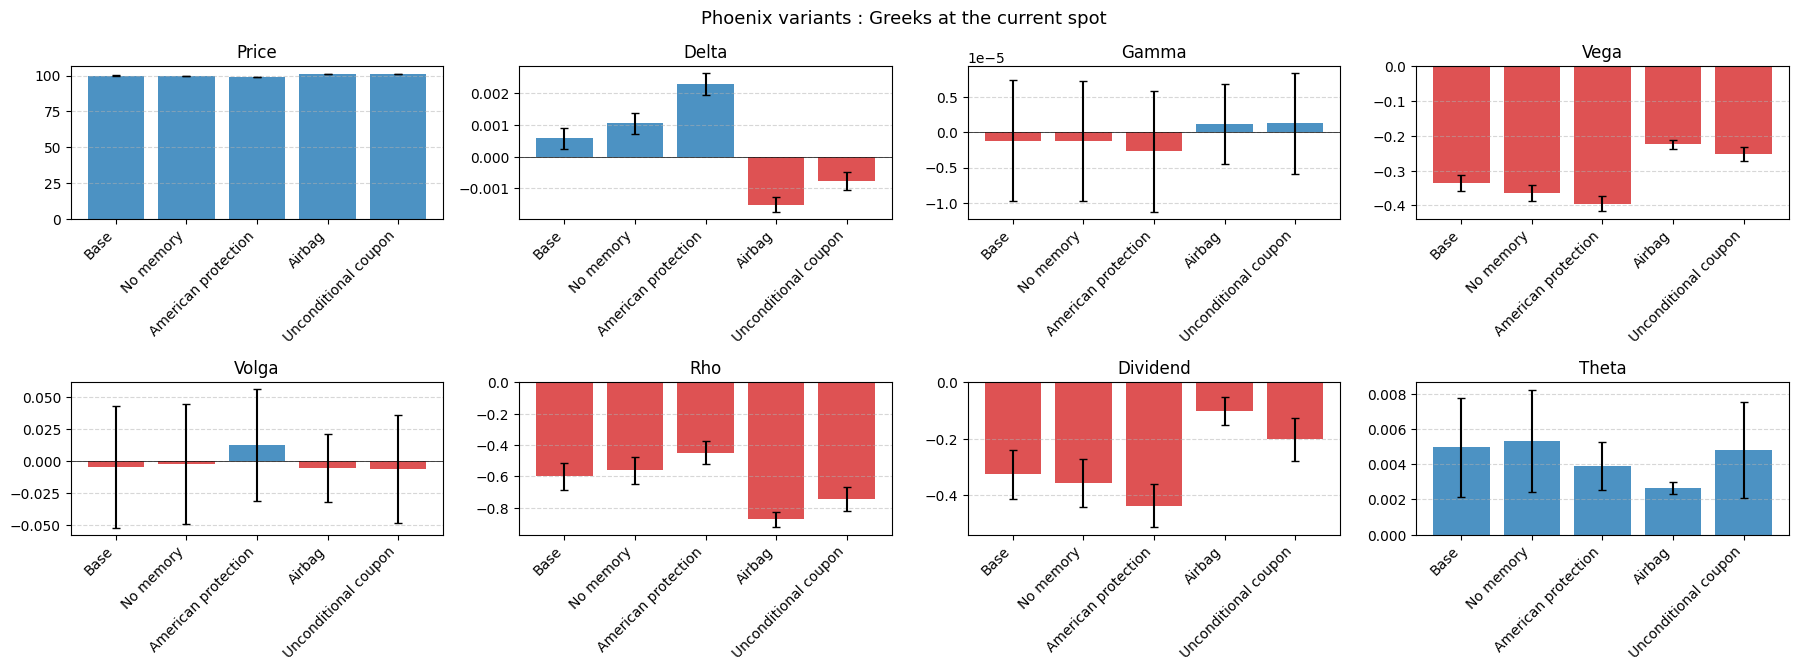

In [10]:
plot_greeks_bars(phoenix_greeks, greeks=("price", "delta", "gamma", "vega", "volga", "rho", "dividend", "theta"),
                 title="Phoenix variants : Greeks at the current spot");

43.9s


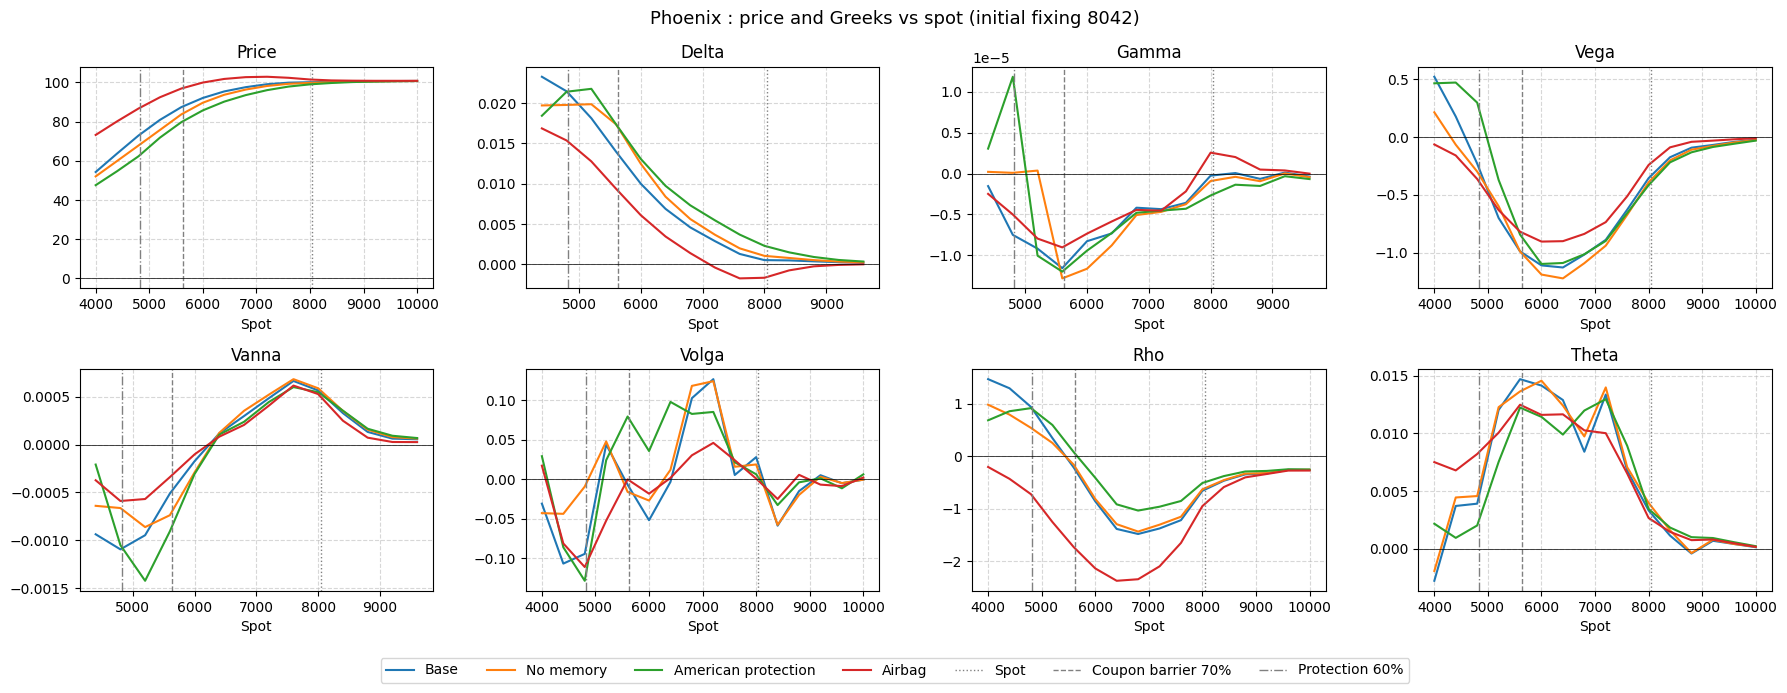

In [11]:
profile_pricer = MonteCarloPricer(n_paths=30_000, steps_per_year=52, seed=42)
spots = np.arange(4000.0, 10001.0, 400.0)
start = time.time()
phoenix_profiles = Greeks(profile_pricer).profiles(heston, notes[:4], spots, labels=labels[:4])
print(f"{time.time() - start:.1f}s")
plot_greek_profiles(phoenix_profiles, vlines={"Spot": S0, "Coupon barrier 70%": 0.7 * S0, "Protection 60%": 0.6 * S0},
                    title="Phoenix : price and Greeks vs spot (initial fixing 8042)");

## 7. Sensitivities to the Heston parameters

In [12]:
pd.concat({label: greeks.parameter_sensitivities(heston, note)["value"] for label, note in zip(labels[:4], notes[:4])}, axis=1)

,Base,No memory,American protection,Airbag
d/dv0,-40.3525,-48.1294,-44.3511,-9.9984
d/dtheta,-44.8981,-46.9892,-57.5223,-38.5666
d/dkappa,-0.192561,-0.204889,-0.698148,-0.128037
d/dxi,1.36478,1.43165,2.22435,-0.352821
d/drho,0.869389,0.831542,0.629678,1.20539


## 8. Limitations

- Single underlying: worst-of / basket phoenix notes need a multi-asset model.
- The fair coupon prices the note at par without issuer margin nor funding / credit spread.
- Euler scheme for the variance (Feller condition violated), Brownian bridge with the variance frozen over each
  week for the continuous protection; the daily-monitored protection is checked on a daily grid.
- Beyond the last listed expiry (4.86 years), the forward curve is extrapolated with a flat carry.